# DAPPr-style evaluation with set-valued epistemic uncertainty

**MNIST · EMNIST Letters · Fashion-MNIST · BloodMNIST**

We adapt the workflow of [DAPPr's train.py](https://github.com/MaxwellYaoNi/DAPPr/blob/main/train.py): train an ID classifier, select a checkpoint by ID validation accuracy, and measure classification confidence and ID/OOD separation. We replace its possibility-based loss and scalar EU with a cross-entropy dropout classifier and a **Probly Representer returning an epistemic interval per input**.

The set varies the weights assigned to a fixed collection of dropout predictions. Its scalar summary is the midpoint of its EU interval; the interval is retained and plotted. This is the requested new method, **not a reproduction of DAPPr's original objective or empirical scores**. The original code's EU is `K / sum(alpha)`, not an average of interval endpoints. See [DAPPr.py](https://github.com/MaxwellYaoNi/DAPPr/blob/main/DAPPr.py) and [the paper](https://arxiv.org/abs/2605.00600).

Each dataset is an independent experiment. As in our previous notebook, classes are split **within each dataset**. Here only ID classes enter training; remaining classes are held-out OOD. There is no unknown-output class or outlier exposure. A small CNN replaces ResNet50 for these 28×28 pilot experiments.

Run in the **reach-aistats** environment (Python 3.13, tested with Probly 0.9.0). Cells are intentionally unexecuted in this notebook. The separate helper `real/epistemic_weight_set.py` holds the numerical solver and the Probly wrapper so both can be tested independently.

In [1]:
from pathlib import Path
import sys, json, copy, math, hashlib, importlib.metadata, inspect
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from PIL import Image
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT/'real/epistemic_weight_set.py').exists():
    ROOT = ROOT/'Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS'
assert (ROOT/'real/epistemic_weight_set.py').exists(), 'Start in REACH_AISTATS or the repository root'
sys.path.insert(0, str(ROOT))
from real.epistemic_weight_set import DropoutEpistemicRepresenter, bound_epistemic, weighted_eu
from probly.quantification import decompose
from probly.representation.distribution.torch_categorical import (
    TorchProbabilityCategoricalDistribution, TorchCategoricalDistributionSample)

plt.rcdefaults()  # avoid optional global plotting styles/fonts from imported packages
CACHE = ROOT/'cache/mnist_reach'
DATASETS = ['mnist', 'emnist', 'fashion', 'blood']
ID_CLASS_COUNT = dict(mnist=4, emnist=13, fashion=4, blood=3)
SEED = 0
TRAIN_PER_CLASS = 400
VAL_PER_CLASS = 80
TEST_PER_CLASS = 100  # None uses all available rows per class
EPOCHS = 15
BATCH_SIZE = 128
LR = 2e-3
WEIGHT_DECAY = 1e-4
WARMUP_EPOCHS = 2
DROPOUT = .5
MC_PASSES = 20
RHO = .5  # fraction of dropout-weight mass allowed to be reassigned
BOUND_TOLERANCE = 1e-5
BOUND_MAX_ITER = 200
SAVE_ARTIFACTS = True
# A fresh directory per run prevents mixing tables/checkpoints across settings.
RUN_DIR = ROOT/'workbook'/('dappr_epistemic_sets_seed' + str(SEED) + '_' + pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ'))
if SAVE_ARTIFACTS:
    RUN_DIR.mkdir(parents=True, exist_ok=False)
torch.set_num_threads(4)
DEVICE = torch.device('cpu')  # explicit reproducible pilot; change to cuda if desired
print('Probly', importlib.metadata.version('probly'), '| Torch', torch.__version__, '|', DEVICE)

Probly 0.9.0 | Torch 2.14.1+cu130 | cpu


## 1. Define what the epistemic set means

For one input, let $p_1,\ldots,p_T$ be the K-class predictions from T dropout passes. With $u_t=1/T$, declare

$$\mathcal W_\rho=\{w=(1-\rho)u+\rho q:\ q\in\Delta^{T-1}\},\qquad 0\leq\rho\leq1.$$

Every dropout member retains weight at least $(1-\rho)/T$; the remaining mass can be reassigned. No OOD label chooses these weights or $\rho$.

For each allowed weight vector, compute the Probly entropy-based mutual information

$$\mathrm{EU}(w;x)=H\!\left(\sum_t w_t p_t(x)\right)-\sum_t w_tH(p_t(x)).$$

Our epistemic set is its image:

$$\mathcal E_\rho(x)=\{\mathrm{EU}(w;x):w\in\mathcal W_\rho\}=[L(x),U(x)].$$

Continuity and connectedness make this image an interval. EU is concave in the weights. The minimum is attained at one of T vertices of $\mathcal W_\rho$. The maximum is solved with Frank–Wolfe steps and a concavity-based tangent upper bound. We retain both `upper_attained` (a feasible value) and `upper` (the outer upper endpoint), with `optimization_gap` between them. All values are in **nats**.

- `rho=0`: the interval collapses to ordinary equal-weight dropout EU.
- `rho=1`: all weights are possible and the lower endpoint is zero because a single member may receive all mass.
- Midpoint `(lower+upper)/2` is the chosen scalar score. It is the mean under a uniform distribution on the **EU interval**, not an expected EU over weights and not a Bayesian estimate.

These endpoints bound this declared finite-sample model family. They are **not confidence or credible intervals** for true epistemic uncertainty. Increasing the set cannot discover hypotheses missing from the dropout sample.

Weights are varied **pointwise per input**; these are not joint bounds under one common posterior weight vector for the whole dataset.

In [2]:
# Read the actual wrapper/solver from the shared helper if you want to inspect it.
print(inspect.getsource(DropoutEpistemicRepresenter))
# Analytic checks: disagreeing deterministic members and identical members.
p = torch.tensor([[[1., 0.], [0., 1.]], [[.8, .2], [.8, .2]]], dtype=torch.float64)
example = bound_epistemic(p, rho=.5)
expected_lower = -.75*math.log(.75)-.25*math.log(.25)
assert abs(example.lower[0].item()-expected_lower) < 1e-9
assert abs(example.upper[0].item()-math.log(2)) < 1e-9
assert example.upper[1] < 1e-9
collapsed = bound_epistemic(p, rho=0)
assert torch.equal(collapsed.lower, collapsed.upper)
display(pd.DataFrame(dict(lower=example.lower.numpy(), upper=example.upper.numpy(),
                         midpoint=example.midpoint.numpy(), nominal_EU=example.nominal_eu.numpy())))

class DropoutEpistemicRepresenter(Representer):
    """Wrap an nn.Module returning logits; __call__/predict return an interval.

    Dropout modules alone are activated, including Dropout2d/3d. Other module
    states and torch RNG state are restored. Bounds depend on rho and the finite
    dropout sample. No ID/OOD labels are supplied to this wrapper.
    """
    def __init__(self, predictor, passes=30, rho=.5, seed=0, tolerance=1e-6, max_iter=200):
        super().__init__(predictor)
        if passes < 2:
            raise ValueError('Use at least two MC passes')
        self.passes, self.rho, self.seed = passes, rho, seed
        self.tolerance, self.max_iter = tolerance, max_iter

    def represent(self, x, *, seed=None):
        model = self.predictor
        modes = {m: m.training for m in model.modules()}
        devices = [x.device.index if x.device.index is not None else torch.cuda.current_device()] if x.is_cuda else []
        try:
            model.eval()
            for mo

,lower,upper,midpoint,nominal_EU
0,0.562335,0.693147,0.627741,0.693147
1,0.000000,0.000000,0.000000,0.000000


## 2. Probly integration and an important weighting check

`DropoutEpistemicRepresenter` subclasses [Probly's Representer](https://github.com/pwhofman/probly/blob/main/src/probly/representer/_representer.py). Calling it returns an `EpistemicInterval` representation rather than raw logits. Its `probabilities`, `lower_weights`, and `upper_weights` retain the model family and endpoint witnesses.

For the equal-weight reference we call `probly.quantification.decompose` on `TorchCategoricalDistributionSample`. For nonuniform weights we use **Probly's categorical entropy primitive** to compute the weighted MI formula explicitly. Inspection of the installed 0.9.0 implementation showed that its sample-MI function averages uniformly even when sample weights are supplied. We do not silently use that path for weighted bounds or modify the installed package. The small check below reports your installed version's behavior.

This is different from Probly's credal-set decomposition `upper_entropy − lower_entropy`, which is one scalar derived from a predictive credal set. Our requested set varies MI across second-order dropout weights.

In [3]:
from probly.representation.distribution.torch_categorical import TorchCategoricalDistributionSample
check_p = torch.tensor([[1., 0.], [0., 1.]], dtype=torch.float64)
check_w = torch.tensor([.9, .1], dtype=torch.float64)
check_sample = TorchCategoricalDistributionSample(
    tensor=TorchProbabilityCategoricalDistribution(check_p), sample_dim=0, weights=check_w)
installed_value = float(decompose(check_sample).epistemic)
explicit_value = float(weighted_eu(check_p, check_w))
print('Installed sample-MI with weights:', installed_value)
print('Explicit weighted MI using Probly entropy:', explicit_value)
print('Installed weighted-sample behavior matches:', np.isclose(installed_value, explicit_value))

Installed sample-MI with weights: 0.6931471805599453
Explicit weighted MI using Probly entropy: 0.3250829733914482
Installed weighted-sample behavior matches: False


## 3. Load cached images

MNIST/EMNIST use official train/test caches with a stratified 80/20 split of official training images for fitting and validation. EMNIST orientation is corrected by transpose. BloodMNIST uses official train/validation/test splits and Pillow RGB-to-grayscale conversion. Images are divided by 255.

Only Fashion's official **test** pool is cached locally. We repartition it 60/20/20 for this pilot, as in the previous notebook. Its reported accuracy is not an official benchmark score. Source indices are retained to check leakage.

,dataset,split,source,rows,classes
0,mnist,train,official_train,47995,10
1,mnist,val,official_train,12005,10
2,mnist,test,official_test,10000,10
3,emnist,train,official_train,99840,26
4,emnist,val,official_train,24960,26
5,emnist,test,official_test,20800,26
6,fashion,train,official_test_repartitioned,6000,10
7,fashion,val,official_test_repartitioned,2000,10
8,fashion,test,official_test_repartitioned,2000,10
9,blood,train,official_train,11959,8


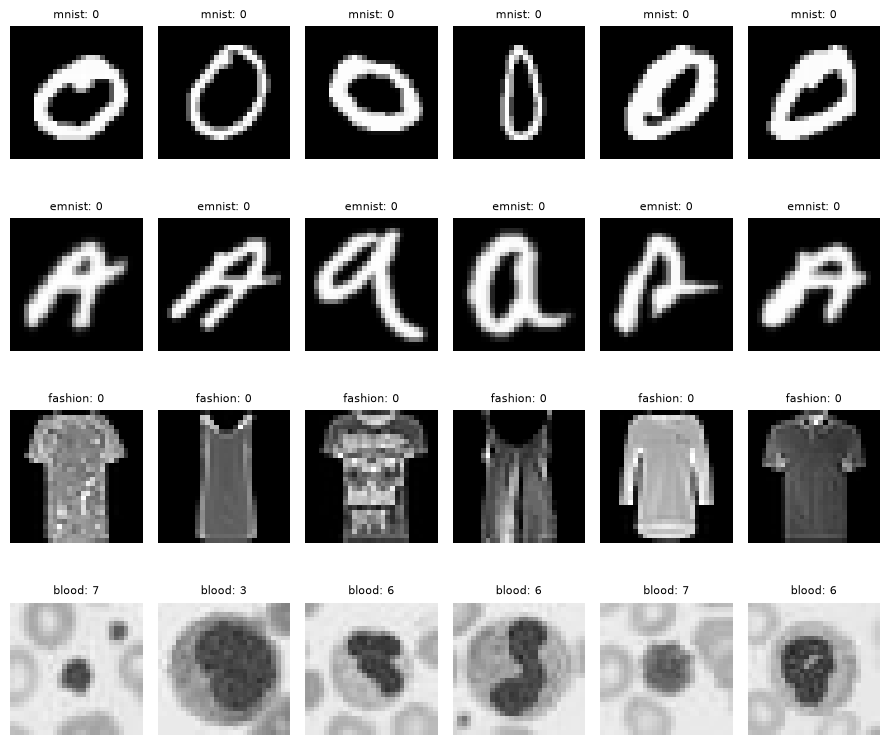

In [4]:
def read_npz(name, split, transpose=False):
    path = CACHE / f'{name}_{split}.npz'
    with np.load(path, allow_pickle=False) as data:
        x, y = data['X'].copy(), data['y'].astype(np.int64).reshape(-1)
    if transpose:
        x = x.transpose(0, 2, 1)
    return np.ascontiguousarray(x), y

def partition_indices(y, fractions, seed):
    rng = np.random.default_rng(seed)
    parts = [[] for _ in fractions]
    for c in np.unique(y):
        ids = rng.permutation(np.flatnonzero(y == c))
        bounds = np.r_[0, (np.cumsum(fractions)[:-1]*len(ids)).astype(int), len(ids)]
        for j in range(len(parts)):
            parts[j].extend(ids[bounds[j]:bounds[j+1]])
    return [np.asarray(p, dtype=np.int64) for p in parts]

def entry(x, y, ids, source):
    return dict(images=x[ids], labels=y[ids], source_index=ids, source=source)

raw = {}
for name in DATASETS:
    if name in ('mnist', 'emnist'):
        cache_name = 'letters' if name == 'emnist' else name
        x, y = read_npz(cache_name, 'train', transpose=name == 'emnist')
        tr, va = partition_indices(y, [.8, .2], SEED + 1)
        raw[name] = {'train': entry(x, y, tr, 'official_train'),
                     'val': entry(x, y, va, 'official_train')}
        x, y = read_npz(cache_name, 'test', transpose=name == 'emnist')
        raw[name]['test'] = entry(x, y, np.arange(len(y)), 'official_test')
    elif name == 'fashion':
        x, y = read_npz('fashion', 'test')
        ids = partition_indices(y, [.6, .2, .2], SEED + 1)
        raw[name] = {split: entry(x, y, ix, 'official_test_repartitioned')
                     for split, ix in zip(['train', 'val', 'test'], ids)}
    elif name == 'blood':
        raw[name] = {}
        with np.load(CACHE / 'bloodmnist_original.npz', allow_pickle=False) as data:
            for split in ['train', 'val', 'test']:
                x = np.stack([np.asarray(Image.fromarray(im).convert('L'))
                              for im in data[f'{split}_images']])
                y = data[f'{split}_labels'].astype(np.int64).reshape(-1)
                raw[name][split] = entry(x, y, np.arange(len(y)), 'official_' + split)
    for pool in raw[name].values():
        assert pool['images'].shape == (len(pool['labels']), 28, 28)
        assert pool['images'].dtype == np.uint8

display(pd.DataFrame([dict(dataset=name, split=split, source=p['source'],
                           rows=len(p['labels']), classes=len(np.unique(p['labels'])))
                      for name, splits in raw.items() for split, p in splits.items()]))
fig, axes = plt.subplots(len(DATASETS), 6, figsize=(9, 2*len(DATASETS)), squeeze=False)
for row, name in enumerate(DATASETS):
    p = raw[name]['train']
    for j, ax in enumerate(axes[row]):
        ax.imshow(p['images'][j], cmap='gray', vmin=0, vmax=255)
        ax.set_title(f"{name}: {p['labels'][j]}", fontsize=8)
        ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Declare ID and OOD class roles

Each dataset receives its own seeded class permutation. Only ID classes enter training and validation checkpoint selection; every remaining class is OOD and used only for final evaluation. Each dataset gets a separate model. Stratified caps control runtime. OOD-vs-ID average precision depends on the sampled prevalence, which is reported explicitly.

In [5]:
worlds, assignments_list, class_list = {}, [], []
for number, name in enumerate(DATASETS):
    seed = SEED + 10*number
    rng = np.random.default_rng(seed)
    labels = np.unique(raw[name]['train']['labels'])
    order = rng.permutation(labels)
    known, unknown = order[:ID_CLASS_COUNT[name]], order[ID_CLASS_COUNT[name]:]
    assert len(known) >= 2 and len(unknown) >= 1
    mapping = {int(c): j for j, c in enumerate(known)}
    w = dict(seed=seed, id_classes=known, ood_classes=unknown, K=len(known))
    for role, classes in [('ID', known), ('OOD', unknown)]:
        class_list.extend(dict(dataset=name, label=int(c), role=role) for c in classes)
    for split, cap in [('train', TRAIN_PER_CLASS), ('val', VAL_PER_CLASS), ('test', TEST_PER_CLASS)]:
        pool = raw[name][split]
        allowed = known if split != 'test' else np.r_[known, unknown]
        chosen = []
        for c in allowed:
            ids = rng.permutation(np.flatnonzero(pool['labels'] == c))
            chosen.extend(ids if cap is None else ids[:cap])
        ids = np.asarray(chosen, dtype=np.int64)
        original_labels = pool['labels'][ids]
        is_ood = ~np.isin(original_labels, known)
        w[split] = dict(images=pool['images'][ids], label=original_labels, is_ood=is_ood,
            target=np.array([mapping.get(int(c), -1) for c in original_labels]),
            source_index=pool['source_index'][ids])
        for i in ids:
            assignments_list.append(dict(dataset=name, split=split, source=pool['source'],
                index=int(pool['source_index'][i]), label=int(pool['labels'][i])))
    assert not w['train']['is_ood'].any() and not w['val']['is_ood'].any()
    worlds[name] = w
assignments = pd.DataFrame(assignments_list)
assert not assignments.duplicated(['dataset', 'source', 'index']).any()
class_roles = pd.DataFrame(class_list)
display(class_roles.groupby(['dataset', 'role']).label.apply(list).to_frame())
display(assignments.groupby(['dataset', 'split']).size().rename('n').to_frame())

label
dataset role                                                  
blood   ID                                           [1, 6, 0]
        OOD                                    [5, 4, 7, 3, 2]
emnist  ID      [7, 9, 11, 5, 17, 25, 19, 6, 1, 4, 15, 18, 10]
        OOD   [23, 14, 3, 16, 2, 12, 20, 8, 21, 22, 0, 13, 24]
fashion ID                                        [8, 7, 4, 0]
        OOD                                 [6, 9, 3, 2, 1, 5]
mnist   ID                                        [4, 6, 2, 7]
        OOD                                 [3, 5, 9, 0, 8, 1]

n
dataset split      
blood   test    800
        train  1200
        val     240
emnist  test   2600
        train  5200
        val    1040
fashion test   1000
        train  1600
        val     320
mnist   test   1000
        train  1600
        val     320

## 5. Train and select checkpoints as in the DAPPr workflow

We keep AdamW, weight decay, warmup/cosine learning-rate scheduling, and selection by ID validation accuracy. We use a smaller CNN and shorter schedule for a runnable pilot, replacing DAPPr's loss with cross-entropy and dropout. The entire network is trained on ID images only; no previously trained all-class backbone is loaded.

The validation metric is deterministic classifier accuracy, matching `train.py`'s model selection. The test wrapper later uses mean dropout probabilities. We defer test/OOD evaluation until after checkpoint selection. The chosen rho is not tuned on OOD scores.

mnist selected epoch 15 validation accuracy 0.9688
emnist selected epoch 14 validation accuracy 0.9231
fashion selected epoch 6 validation accuracy 0.9688
blood selected epoch 15 validation accuracy 0.9125


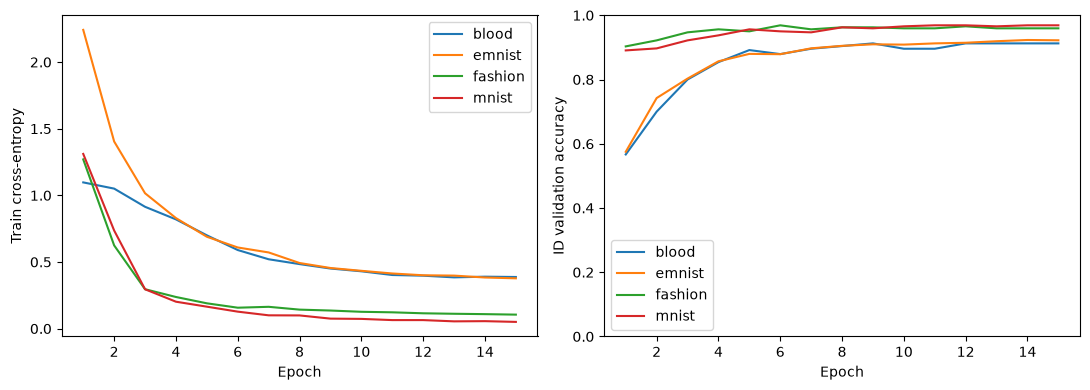

In [6]:
class DropoutCNN(nn.Module):
    def __init__(self, k):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(),
            nn.Linear(32*7*7, 64), nn.ReLU(), nn.Dropout(DROPOUT), nn.Linear(64, k))
    def forward(self, x):
        return self.net(x)

def image_tensor(images):
    return torch.from_numpy(np.ascontiguousarray(images)).float()[:, None]/255.

def validation_accuracy(model, x, y):
    model.eval()
    correct = 0
    with torch.no_grad():
        for start in range(0, len(x), BATCH_SIZE):
            pred = model(x[start:start+BATCH_SIZE].to(DEVICE)).argmax(1).cpu()
            correct += (pred == y[start:start+BATCH_SIZE]).sum().item()
    return correct/len(y)

history_rows = []
for name, w in worlds.items():
    torch.manual_seed(w['seed'])
    model = DropoutCNN(w['K']).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    x = image_tensor(w['train']['images'])
    y = torch.from_numpy(w['train']['target']).long()
    xv = image_tensor(w['val']['images'])
    yv = torch.from_numpy(w['val']['target']).long()
    loader = DataLoader(TensorDataset(x, y), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(w['seed']))
    best_acc, best_state, best_epoch = -1., None, None
    for epoch in range(EPOCHS):
        if epoch < WARMUP_EPOCHS:
            lr = LR*(epoch+1)/max(1, WARMUP_EPOCHS)
        else:
            progress = (epoch-WARMUP_EPOCHS)/max(1, EPOCHS-WARMUP_EPOCHS-1)
            lr = 1e-5+(LR-1e-5)*.5*(1+math.cos(math.pi*progress))
        for group in optimizer.param_groups:
            group['lr'] = lr
        model.train()
        total = 0.
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = nn.functional.cross_entropy(model(xb.to(DEVICE)), yb.to(DEVICE))
            loss.backward(); optimizer.step()
            total += loss.item()*len(yb)
        val_acc = validation_accuracy(model, xv, yv)
        history_rows.append(dict(dataset=name, epoch=epoch+1, loss=total/len(y), val_accuracy=val_acc, lr=lr))
        if val_acc >= best_acc:
            best_acc, best_epoch = val_acc, epoch+1
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    model.eval()
    w.update(model=model, best_epoch=best_epoch, best_val_accuracy=best_acc)
    print(name, 'selected epoch', best_epoch, 'validation accuracy', round(best_acc, 4))
history = pd.DataFrame(history_rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, sub in history.groupby('dataset'):
    axes[0].plot(sub.epoch, sub.loss, label=name)
    axes[1].plot(sub.epoch, sub.val_accuracy, label=name)
axes[0].set(xlabel='Epoch', ylabel='Train cross-entropy')
axes[1].set(xlabel='Epoch', ylabel='ID validation accuracy', ylim=(0, 1))
axes[0].legend(); axes[1].legend(); plt.tight_layout(); plt.show()

## 6. Replace raw outputs with interval representations

The interface is `representation = wrapper(images)`, then `representation.lower`, `.upper`, `.midpoint`, and `.optimization_gap`. The wrapper never receives ID/OOD labels. MC dropout changes only dropout modules and restores module/RNG states after inference.

Each batched inference call returns one interval per image; batching is recorded through the configuration and seeds. We retain the sampled probabilities for the same-draw rho sensitivity analysis below. Midpoint uncertainty is not a class prediction: class predictions use the equal-weight predictive mean.

In [7]:
def collect_intervals(w, split, seed_offset):
    wrapper = DropoutEpistemicRepresenter(w['model'], passes=MC_PASSES, rho=RHO,
        seed=w['seed']+seed_offset, tolerance=BOUND_TOLERANCE, max_iter=BOUND_MAX_ITER)
    x = image_tensor(w[split]['images'])
    frames, probability_chunks = [], []
    for batch, start in enumerate(range(0, len(x), BATCH_SIZE)):
        rep = wrapper(x[start:start+BATCH_SIZE].to(DEVICE), seed=w['seed']+seed_offset+batch)
        arrays = {key: getattr(rep, key).detach().cpu().numpy() for key in
                  ['lower', 'upper', 'upper_attained', 'midpoint', 'width', 'optimization_gap',
                   'nominal_eu', 'nominal_tu', 'nominal_au']}
        arrays['prediction'] = rep.mean_probabilities.argmax(1).cpu().numpy()
        arrays['negative_msp'] = -rep.mean_probabilities.max(1).values.cpu().numpy()
        frames.append(pd.DataFrame(arrays))
        probability_chunks.append(rep.probabilities.cpu())
    return pd.concat(frames, ignore_index=True), torch.cat(probability_chunks)

result_frames, cal_rows = [], []
for name, w in worlds.items():
    cal, _ = collect_intervals(w, 'val', 10000)
    w['threshold'] = float(cal.midpoint.quantile(.95))
    cal_rows.append(dict(dataset=name, midpoint_ID_q95=w['threshold'], best_epoch=w['best_epoch'],
                        selected_validation_accuracy=w['best_val_accuracy']))
    frame, probs = collect_intervals(w, 'test', 20000)
    frame['dataset'] = name
    frame['is_ood'] = w['test']['is_ood']
    frame['original_label'] = w['test']['label']
    frame['target'] = w['test']['target']
    frame['source_index'] = w['test']['source_index']
    frame['test_position'] = np.arange(len(frame))
    w['scores'], w['probabilities'] = frame, probs
    result_frames.append(frame)
    print(name, 'rows', len(frame), 'max endpoint gap', f'{frame.optimization_gap.max():.3g}', 'nats')
results = pd.concat(result_frames, ignore_index=True)
calibration = pd.DataFrame(cal_rows)
summary = results.groupby(['dataset', 'is_ood']).agg(n=('lower', 'size'),
    mean_lower=('lower', 'mean'), mean_upper=('upper', 'mean'), mean_midpoint=('midpoint', 'mean'),
    mean_nominal_EU=('nominal_eu', 'mean'), mean_width=('width', 'mean'), max_solver_gap=('optimization_gap', 'max'))
display(summary.round(5))
print('Rows with solver gap above tolerance:', int((results.optimization_gap > BOUND_TOLERANCE).sum()))

mnist rows 1000 max endpoint gap 0.000141 nats
emnist rows 2600 max endpoint gap 0.000191 nats
fashion rows 1000 max endpoint gap 3.39e-05 nats
blood rows 800 max endpoint gap 5.78e-05 nats


n  mean_lower  mean_upper  mean_midpoint  mean_nominal_EU  \
dataset is_ood                                                                 
blood   False    300     0.03441     0.12915        0.08178          0.06646   
        True     500     0.03320     0.12861        0.08090          0.06434   
emnist  False   1300     0.14652     0.41819        0.28236          0.25509   
        True    1300     0.27783     0.65260        0.46521          0.47309   
fashion False    400     0.03745     0.14366        0.09056          0.07056   
        True     600     0.05620     0.19746        0.12683          0.10630   
mnist   False    400     0.02112     0.08541        0.05326          0.03950   
        True     600     0.08933     0.29339        0.19136          0.16879   

                mean_width  max_solver_gap  
dataset is_ood                              
blood   False      0.09474         0.00002  
        True       0.09541         0.00006  
emnist  False      0.27166         0.00011  
        True       0.37477         0.00019  
fashion False      0.10621         0.00003  
        True       0.14126         0.00001  
mnist   False      0.06429         0.00001  
        True       0.20406         0.00014

Rows with solver gap above tolerance: 33


## 7. DAPPr-compatible scalar evaluation, with explicit score orientation

The original `train.py`'s OOD AUPR function treats **ID as positive** and negates uncertainty. We reproduce that convention as `AUPR_ID_positive`, and also report the more common OOD-positive AUPR and AUROC. Both AUPRs depend on the observed ID/OOD prevalence.

The main score is `midpoint`; lower and upper endpoints, width, equal-weight MI, total entropy and negative maximum probability are comparisons. ID classification accuracy and correctness-positive confidence AUPR use the dropout mean prediction. None of these metrics train or select the model.

In [8]:
metric_rows, accuracy_rows = [], []
for name, w in worlds.items():
    f = w['scores']
    y_ood = f.is_ood.to_numpy().astype(int)
    id_rows = ~f.is_ood
    correct = (f.loc[id_rows, 'prediction'] == f.loc[id_rows, 'target']).to_numpy()
    accuracy_rows.append(dict(dataset=name, test_ID_accuracy=correct.mean(), n_ID=int(id_rows.sum()),
        n_OOD=int(f.is_ood.sum()), OOD_prevalence=y_ood.mean(), selected_epoch=w['best_epoch']))
    for score_name in ['midpoint', 'lower', 'upper', 'width', 'nominal_eu', 'nominal_tu', 'negative_msp']:
        values = f[score_name].to_numpy()
        assert np.isfinite(values).all()
        fpr, tpr, _ = roc_curve(y_ood, values)
        metric_rows.append(dict(dataset=name, score=score_name,
            AUROC_OOD=roc_auc_score(y_ood, values),
            AUPR_OOD_positive=average_precision_score(y_ood, values),
            AUPR_ID_positive=average_precision_score(1-y_ood, -values),
            FPR95=fpr[np.flatnonzero(tpr >= .95)[0]],
            confidence_AUPR_correct=(average_precision_score(correct, -values[id_rows])
                                     if np.unique(correct).size == 2 else np.nan)))
metrics = pd.DataFrame(metric_rows)
accuracy = pd.DataFrame(accuracy_rows)
display(accuracy.round(4))
display(metrics.round(4))

,dataset,test_ID_accuracy,n_ID,n_OOD,OOD_prevalence,selected_epoch
0,mnist,0.9750,400,600,0.600,15
1,emnist,0.9346,1300,1300,0.500,14
2,fashion,0.9475,400,600,0.600,6
3,blood,0.9100,300,500,0.625,15


,dataset,score,AUROC_OOD,AUPR_OOD_positive,AUPR_ID_positive,FPR95,confidence_AUPR_correct
0,mnist,midpoint,0.8815,0.9007,0.8250,0.5475,0.9976
1,mnist,lower,0.8962,0.9173,0.8393,0.5125,0.9979
2,mnist,upper,0.8762,0.8942,0.8205,0.5600,0.9975
3,mnist,width,0.8641,0.8806,0.8103,0.5650,0.9974
4,mnist,nominal_eu,0.8974,0.9174,0.8403,0.5150,0.9981
5,mnist,nominal_tu,0.9239,0.9484,0.8687,0.4525,0.9990
6,mnist,negative_msp,0.9232,0.9476,0.8682,0.4475,0.9989
7,emnist,midpoint,0.7943,0.8014,0.7710,0.7385,0.9730
8,emnist,lower,0.8150,0.8192,0.7923,0.7300,0.9775
9,emnist,upper,0.7800,0.7863,0.7587,0.7477,0.9705


## 8. Plot the epistemic limits for ID and OOD

**Main requested figure:** each vertical interval is one image's `[lower, upper]`; black points are interval midpoints, and orange dots are ordinary dropout EU. Select up to 80 images per group without looking at their uncertainty, then sort those selected images by midpoint for readability. ID and OOD share axes within each dataset. The shaded/vertical ranges are uncertainty sets, not confidence bands.

The faint dotted upper trace marks the attained maximum. A visible gap between it and the upper limit indicates unresolved numerical optimization, not epistemic width.

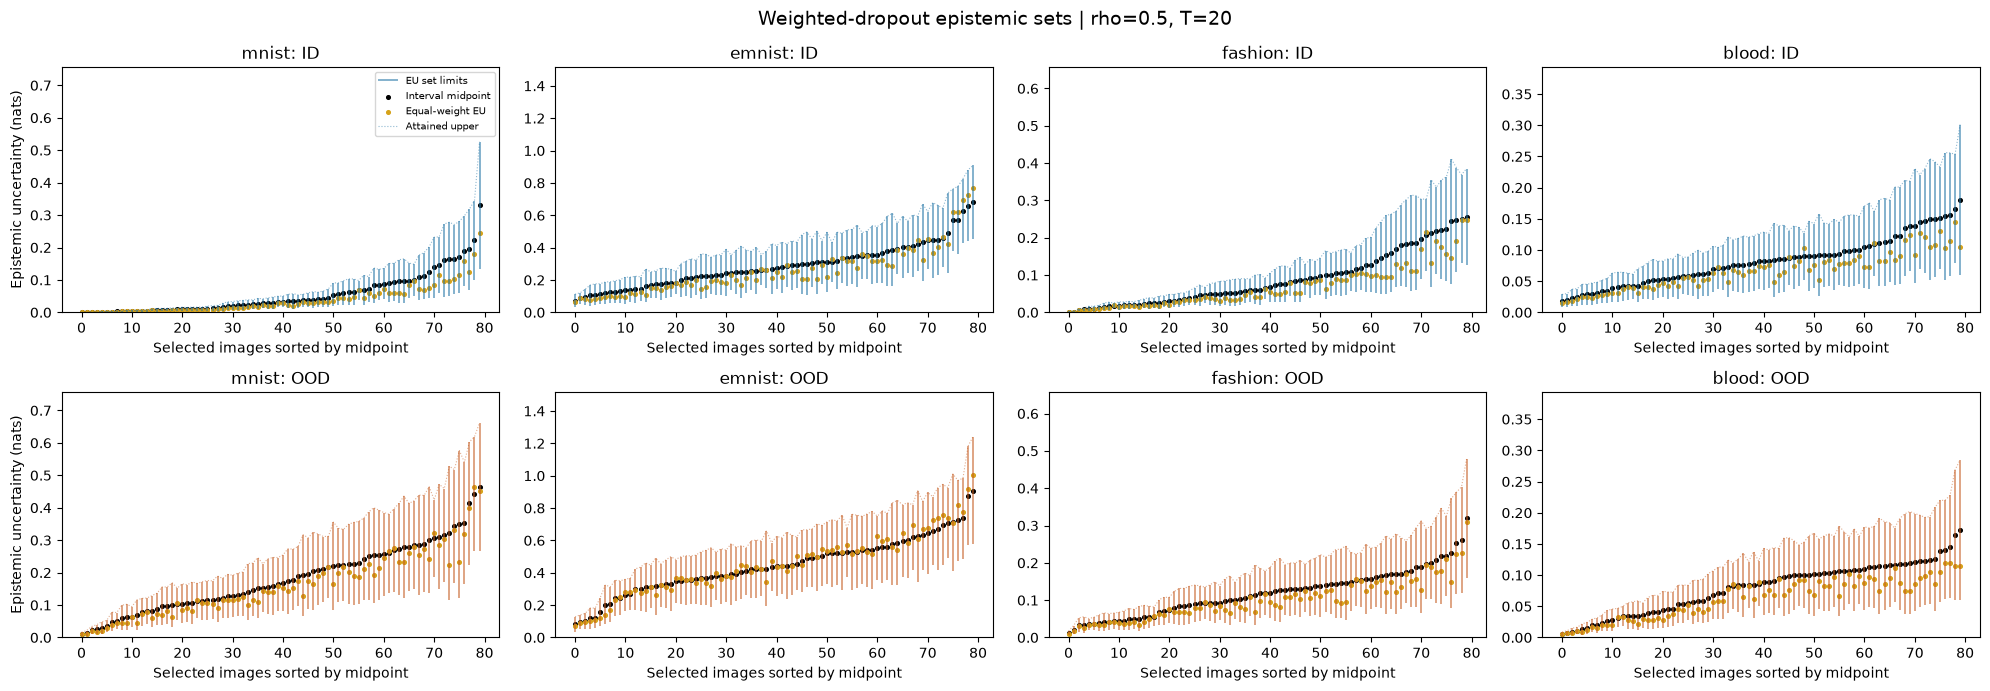

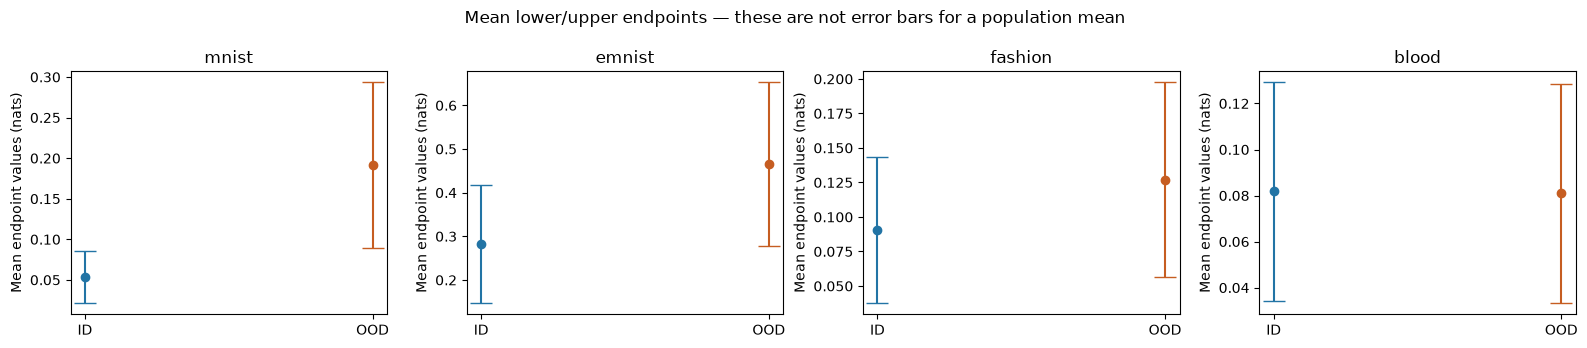

In [9]:
fig, axes = plt.subplots(2, len(DATASETS), figsize=(5*len(DATASETS), 7), squeeze=False)
for col, name in enumerate(DATASETS):
    f = worlds[name]['scores']
    ymax = max(float(f.upper.max())*1.05, 1e-5)
    for row, (ood, label, color) in enumerate([(False, 'ID', '#2274a5'), (True, 'OOD', '#c65d21')]):
        sub = f[f.is_ood == ood].sample(n=min(80, int((f.is_ood == ood).sum())), random_state=SEED)
        sub = sub.sort_values('midpoint')
        x = np.arange(len(sub))
        ax = axes[row, col]
        ax.vlines(x, sub.lower, sub.upper, color=color, alpha=.65, lw=1.2, label='EU set limits')
        ax.scatter(x, sub.midpoint, c='black', s=7, label='Interval midpoint')
        ax.scatter(x, sub.nominal_eu, c='#d6a219', s=7, label='Equal-weight EU')
        ax.plot(x, sub.upper_attained, ':', color=color, alpha=.5, lw=.8, label='Attained upper')
        ax.set(title=f'{name}: {label}', xlabel='Selected images sorted by midpoint', ylim=(0, ymax))
        if col == 0: ax.set_ylabel('Epistemic uncertainty (nats)')
axes[0, 0].legend(fontsize=7)
fig.suptitle(f'Weighted-dropout epistemic sets | rho={RHO}, T={MC_PASSES}', fontsize=14)
fig.tight_layout()
if SAVE_ARTIFACTS:
    fig.savefig(RUN_DIR/'epistemic_limits.png', dpi=180, bbox_inches='tight')
    fig.savefig(RUN_DIR/'epistemic_limits.pdf', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, len(DATASETS), figsize=(4*len(DATASETS), 3.5), squeeze=False)
for ax, name in zip(axes[0], DATASETS):
    f = worlds[name]['scores']
    for j, (ood, color) in enumerate([(False, '#2274a5'), (True, '#c65d21')]):
        sub = f[f.is_ood == ood]
        lower, upper, midpoint = sub.lower.mean(), sub.upper.mean(), sub.midpoint.mean()
        ax.errorbar(j, midpoint, yerr=np.array([[midpoint-lower], [upper-midpoint]]),
                    fmt='o', color=color, capsize=8)
    ax.set(title=name, xticks=[0, 1], xticklabels=['ID', 'OOD'], ylabel='Mean endpoint values (nats)')
fig.suptitle('Mean lower/upper endpoints — these are not error bars for a population mean')
fig.tight_layout()
if SAVE_ARTIFACTS: fig.savefig(RUN_DIR/'mean_epistemic_limits.png', dpi=180, bbox_inches='tight')
plt.show()

## 9. Inspect image-level intervals

Display four images per dataset: an ID example near the median midpoint, the highest-midpoint ID example, an OOD example near the median, and the lowest-midpoint OOD example. Selection is explicit: these panels illustrate typical/extreme behavior, not prevalence. A narrow low-EU OOD interval is possible if dropout members agree on an incorrect known-class prediction.

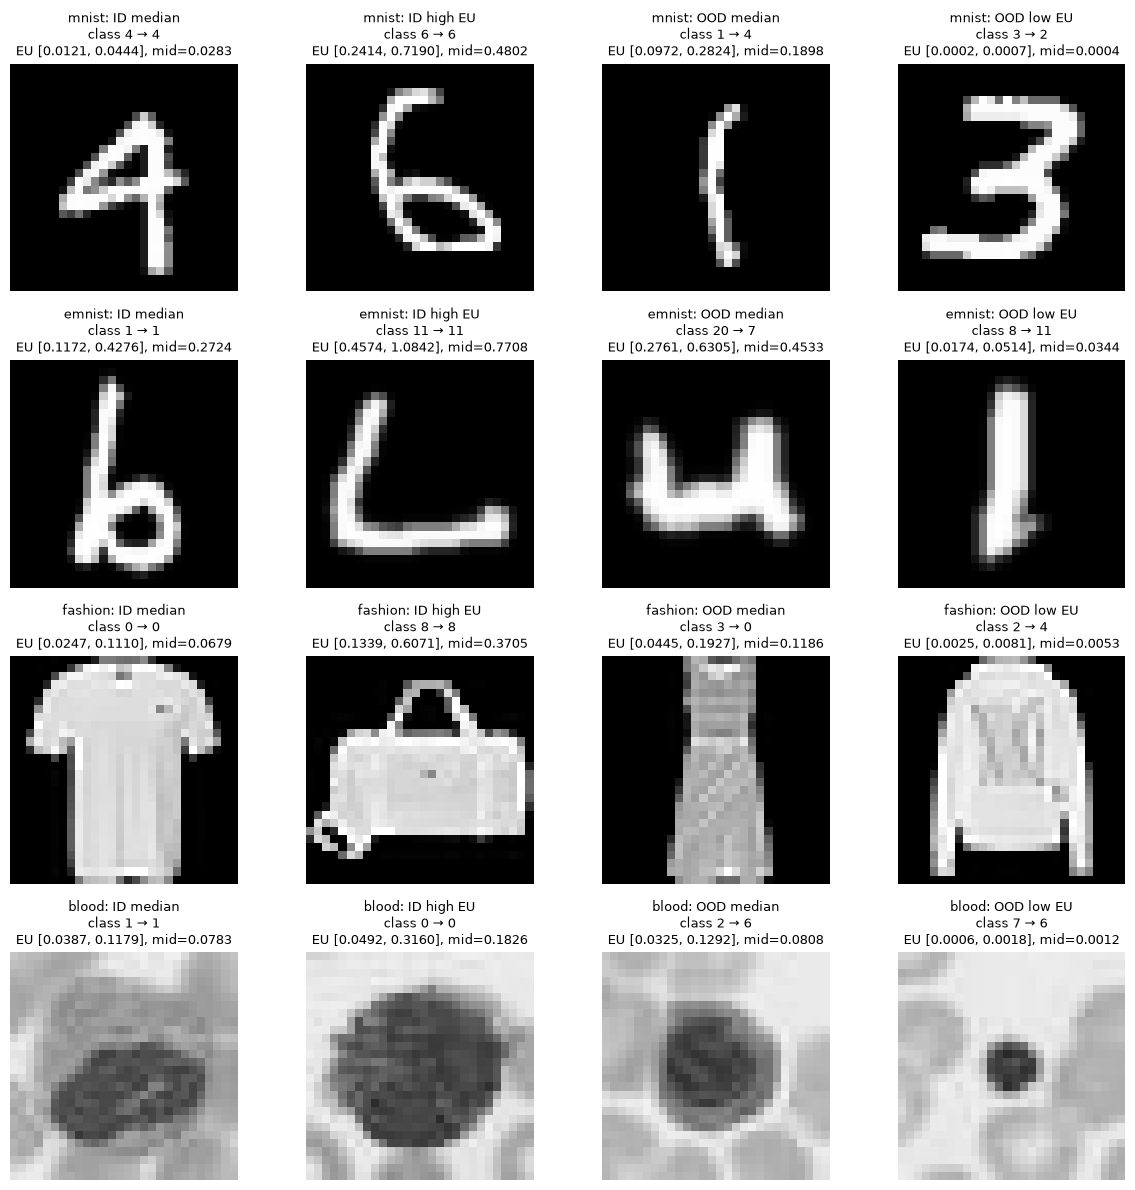

In [10]:
fig, axes = plt.subplots(len(DATASETS), 4, figsize=(12, 3*len(DATASETS)), squeeze=False)
for row, name in enumerate(DATASETS):
    w = worlds[name]
    idf = w['scores'][~w['scores'].is_ood].sort_values('midpoint')
    oodf = w['scores'][w['scores'].is_ood].sort_values('midpoint')
    examples = [('ID median', idf.iloc[len(idf)//2]), ('ID high EU', idf.iloc[-1]),
                ('OOD median', oodf.iloc[len(oodf)//2]), ('OOD low EU', oodf.iloc[0])]
    for ax, (label, sample) in zip(axes[row], examples):
        ax.imshow(w['test']['images'][int(sample.test_position)], cmap='gray', vmin=0, vmax=255)
        predicted_class = w['id_classes'][int(sample.prediction)]
        ax.set_title(f'{name}: {label}\nclass {int(sample.original_label)} → {predicted_class}\n'
                     f'EU [{sample.lower:.4f}, {sample.upper:.4f}], mid={sample.midpoint:.4f}', fontsize=9)
        ax.axis('off')
fig.tight_layout()
if SAVE_ARTIFACTS: fig.savefig(RUN_DIR/'image_epistemic_sets.png', dpi=180, bbox_inches='tight')
plt.show()

## 10. Sensitivity to rho, on the same dropout predictions

Rho specifies the ambiguity set and is a modeling choice, not a confidence level. Increasing rho enlarges the weight family: the exact lower bound cannot increase and the exact upper bound cannot decrease. At rho=1 the lower endpoint is necessarily zero. We reuse a stratified subset of already evaluated predictions so differences come from the weight set, not new dropout draws. Numerical upper endpoints can differ by their reported solver gaps.

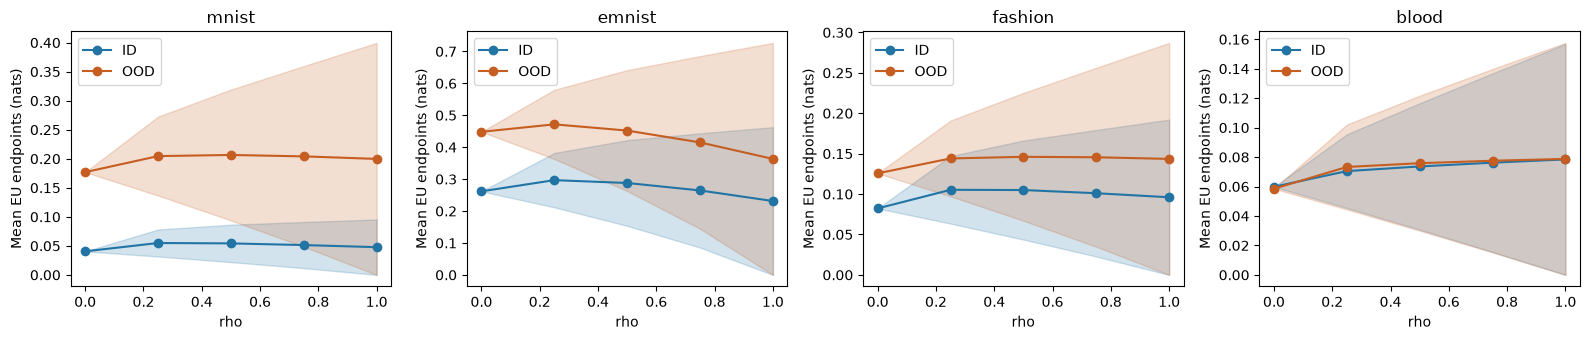

In [11]:
sensitivity_rows = []
for name, w in worlds.items():
    for ood in [False, True]:
        ids = np.flatnonzero(w['test']['is_ood'] == ood)
        ids = np.random.default_rng(SEED).permutation(ids)[:40]
        p = w['probabilities'][ids]
        for rho in [0., .25, .5, .75, 1.]:
            rep = bound_epistemic(p, rho=rho, tolerance=BOUND_TOLERANCE, max_iter=BOUND_MAX_ITER)
            sensitivity_rows.append(dict(dataset=name, is_ood=ood, rho=rho,
                lower=rep.lower.mean().item(), upper=rep.upper.mean().item(),
                midpoint=rep.midpoint.mean().item(), max_solver_gap=rep.optimization_gap.max().item()))
sensitivity = pd.DataFrame(sensitivity_rows)
fig, axes = plt.subplots(1, len(DATASETS), figsize=(4*len(DATASETS), 3.5), squeeze=False)
for ax, name in zip(axes[0], DATASETS):
    for ood, label, color in [(False, 'ID', '#2274a5'), (True, 'OOD', '#c65d21')]:
        f = sensitivity[(sensitivity.dataset == name) & (sensitivity.is_ood == ood)]
        ax.fill_between(f.rho, f.lower, f.upper, alpha=.2, color=color)
        ax.plot(f.rho, f.midpoint, 'o-', color=color, label=label)
    ax.set(title=name, xlabel='rho', ylabel='Mean EU endpoints (nats)'); ax.legend()
fig.tight_layout()
if SAVE_ARTIFACTS: fig.savefig(RUN_DIR/'rho_sensitivity.png', dpi=180, bbox_inches='tight')
plt.show()

## 11. Threshold decisions from sets

Set a single threshold from the 95th percentile of validation-ID **midpoint** scores. At test time, an interval entirely above it is “high EU for all allowed weights”; entirely below it is “low EU for all allowed weights”; otherwise the decision depends on weights. These are relative score statements—not certificates of ID membership or OOD status.

The midpoint rule has approximately 5% exceedances on validation ID only (ties and quantiles can change this). Neither endpoint rule inherits a 5% error guarantee. Low-EU OOD rows remain possible; a larger ambiguity set does not ensure successful OOD detection.

In [12]:
decision_frames = []
for name, w in worlds.items():
    f = w['scores'].copy()
    threshold = w['threshold']
    f['all_weights_high'] = f.lower > threshold
    f['all_weights_low'] = f.upper <= threshold
    f['weight_sensitive'] = ~(f.all_weights_high | f.all_weights_low)
    f['midpoint_high'] = f.midpoint > threshold
    decision_frames.append(f)
decisions = pd.concat(decision_frames)
decision_summary = decisions.groupby(['dataset', 'is_ood'])[
    ['all_weights_high', 'all_weights_low', 'weight_sensitive', 'midpoint_high']].mean()
display(calibration.round(4))
display(decision_summary.round(4))

,dataset,midpoint_ID_q95,best_epoch,selected_validation_accuracy
0,mnist,0.1879,15,0.9688
1,emnist,0.5396,14,0.9231
2,fashion,0.2229,6,0.9688
3,blood,0.1472,15,0.9125


all_weights_high  all_weights_low  weight_sensitive  \
dataset is_ood                                                        
blood   False             0.0000           0.6633            0.3367   
        True              0.0000           0.6000            0.4000   
emnist  False             0.0000           0.7492            0.2508   
        True              0.0300           0.3185            0.6515   
fashion False             0.0000           0.7750            0.2250   
        True              0.0017           0.6167            0.3817   
mnist   False             0.0050           0.8575            0.1375   
        True              0.0350           0.2467            0.7183   

                midpoint_high  
dataset is_ood                 
blood   False          0.0633  
        True           0.0740  
emnist  False          0.0377  
        True           0.3185  
fashion False          0.0575  
        True           0.0983  
mnist   False          0.0550  
        True           0.5100

## 12. Save reproducible artifacts and read the result

The export pairs source-image assignments, class roles, selected checkpoints, thresholds, scalar metrics, per-image endpoints, finite dropout predictions and all figures. Solver gaps are saved per row. Repeating training/class seeds and varying the number of MC passes are separate robustness experiments; the current bounds condition on one trained network and the finite draws.

A useful result would show stronger ID/OOD separation without poor ID classification, with endpoint gaps small relative to the differences being interpreted. The interval and scalar midpoint are compared with ordinary dropout EU using the same predictions. Wider intervals alone do not imply better OOD detection, and these pilot results do not establish superiority over DAPPr.

In [13]:
if SAVE_ARTIFACTS:
    config = dict(seed=SEED, datasets=DATASETS, id_class_count=ID_CLASS_COUNT,
        train_per_class=TRAIN_PER_CLASS, val_per_class=VAL_PER_CLASS, test_per_class=TEST_PER_CLASS,
        epochs=EPOCHS, batch_size=BATCH_SIZE, learning_rate=LR, weight_decay=WEIGHT_DECAY,
        warmup_epochs=WARMUP_EPOCHS, dropout=DROPOUT, mc_passes=MC_PASSES, rho=RHO,
        bound_tolerance=BOUND_TOLERANCE, bound_max_iter=BOUND_MAX_ITER, device=str(DEVICE),
        torch_version=str(torch.__version__), probly_version=importlib.metadata.version('probly'),
        helper_sha256=hashlib.sha256((ROOT/'real/epistemic_weight_set.py').read_bytes()).hexdigest(),
        set_definition='w=(1-rho)/T+rho*q; q in simplex',
        scalar_score='midpoint of lower and numerical outer upper endpoint',
        fashion_protocol='official test pool repartitioned 60/20/20')
    (RUN_DIR/'config.json').write_text(json.dumps(config, indent=2))
    for title, table in [('assignments', assignments), ('class_roles', class_roles), ('history', history),
                         ('scores', results), ('metrics', metrics), ('accuracy', accuracy),
                         ('calibration', calibration), ('sensitivity', sensitivity)]:
        table.to_csv(RUN_DIR/f'{title}.csv', index=False)
    summary.to_csv(RUN_DIR/'summary.csv')
    decision_summary.to_csv(RUN_DIR/'decision_summary.csv')
    for name, w in worlds.items():
        torch.save({k: v.cpu() for k, v in w['model'].state_dict().items()}, RUN_DIR/f'{name}_model.pt')
        np.savez_compressed(RUN_DIR/f'{name}_dropout_predictions.npz', probabilities=w['probabilities'].numpy())
    print('Saved:', RUN_DIR)

Saved: /home/mtleao/projects/Concept_Disentaglement/Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS/workbook/dappr_epistemic_sets_seed0_20261029T085507170686Z
